# ITCS 6169/8169 Assignment 1 — CNN Scene Recognition

**Final result:** 96.75% test accuracy (387/400), 96.74% test macro-F1, and 96.88% validation accuracy.

The final classifier is an ImageNet-1K-pretrained ConvNeXt-Small with a training-only masked-patch prediction objective. This notebook summarizes the reproducible experiment; training code, exact configurations, aggregate results, tests, and the compact checkpoint are stored alongside it.

In [1]:
from pathlib import Path
import csv, json, platform
import torch, torchvision

ROOT = Path.cwd()
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Python: 3.10.0
PyTorch: 2.14.1+cu130
torchvision: 0.29.1+cu130
CUDA available: True


## 1. Data and validation protocol

- 2,400 training images and 400 test images across 16 balanced classes.
- Fixed 80/20 development split: 1,920 training and 480 validation images, with 30 validation images per class.
- SHA-256 duplicate groups are kept entirely on one side of the split; no train/test exact duplicates were found.
- The unusual image-mode artifact is disclosed: all 175 RGB images belong to `Flower`; the remaining 2,625 images are grayscale. A grayscale control showed that this did not explain the overall performance gain.
- Training never evaluates the test loader. `evaluate.py` requires `--confirm-final-test` for test evaluation.

In [2]:
audit = json.loads((ROOT / "results/data_audit.json").read_text())
selection = json.loads((ROOT / "results/final_selection.json").read_text())
print("Selected recipe:", selection["selected_recipe"])
print(f"Validation accuracy: {100 * selection['validation_accuracy']:.2f}%")
print(f"Test accuracy:       {100 * selection['test_accuracy']:.2f}%")
print(f"Test macro-F1:       {100 * selection['test_macro_f1']:.2f}%")

Selected recipe: E9 ImageNet-pretrained ConvNeXt-Small with masked patch auxiliary loss
Validation accuracy: 96.88%
Test accuracy:       96.75%
Test macro-F1:       96.74%


## 2. Final training recipe

- **CNN:** torchvision ConvNeXt-Small, 49.47M parameters, official supervised ImageNet-1K initialization; every parameter is fine-tuned.
- **Input:** 224×224 RGB, ImageNet normalization.
- **Augmentation:** random resized crop retaining 82–100% of the scene, horizontal flip, ±5° rotation, mild color jitter, and 10% random erasing.
- **Optimization:** AdamW; backbone LR `2e-5`, head LR `3e-4`, weight decay `0.01`, cosine schedule to `5e-7`, batch size 32, label smoothing 0.1, dropout 0.2, AMP, gradient clipping 5.0, and early stopping patience 8.
- **Auxiliary task:** mask 40% of 32×32 blocks and predict the masked blocks' average normalized RGB values from the 7×7 ConvNeXt feature map. Its MSE weight is 0.2. The auxiliary head is not used for classification inference.
- **Selection:** best validation-accuracy checkpoint, epoch 10; stopped at epoch 18.

In [3]:
with (ROOT / "results/experiment_results.csv").open(newline="") as handle:
    rows = list(csv.DictReader(handle))

print(f"{'Experiment':44s} {'Seed':>4s} {'Val acc.':>9s}")
print("-" * 61)
for row in rows:
    print(f"{row['experiment'][:44]:44s} {row['seed']:>4s} {100*float(row['validation_accuracy']):8.2f}%")

Experiment                                   Seed  Val acc.
-------------------------------------------------------------
E0 Starter TNet                                 0    45.42%
E1 SceneCNN                                     0    80.83%
E2 ResNet18                                     0    89.58%
E2 ResNet18                                     1    91.67%
E2 ResNet18                                     2    90.62%
E3 ConvMAE + ResNet18                           0    90.83%
E3 ConvMAE + ResNet18                           1    90.21%
E3 ConvMAE + ResNet18                           2    90.42%
E5 ResNet18 gray                                0    89.79%
E6 ResNet18 224px                               0    92.71%
E7 ConvNeXt-Small                               0    97.08%
E7 ConvNeXt-Small                               1    96.67%
E7 ConvNeXt-Small                               2    96.88%
E8 ConvNeXt-Base                                0    95.21%
E9 ConvNeXt-Small + masked auxiliary  

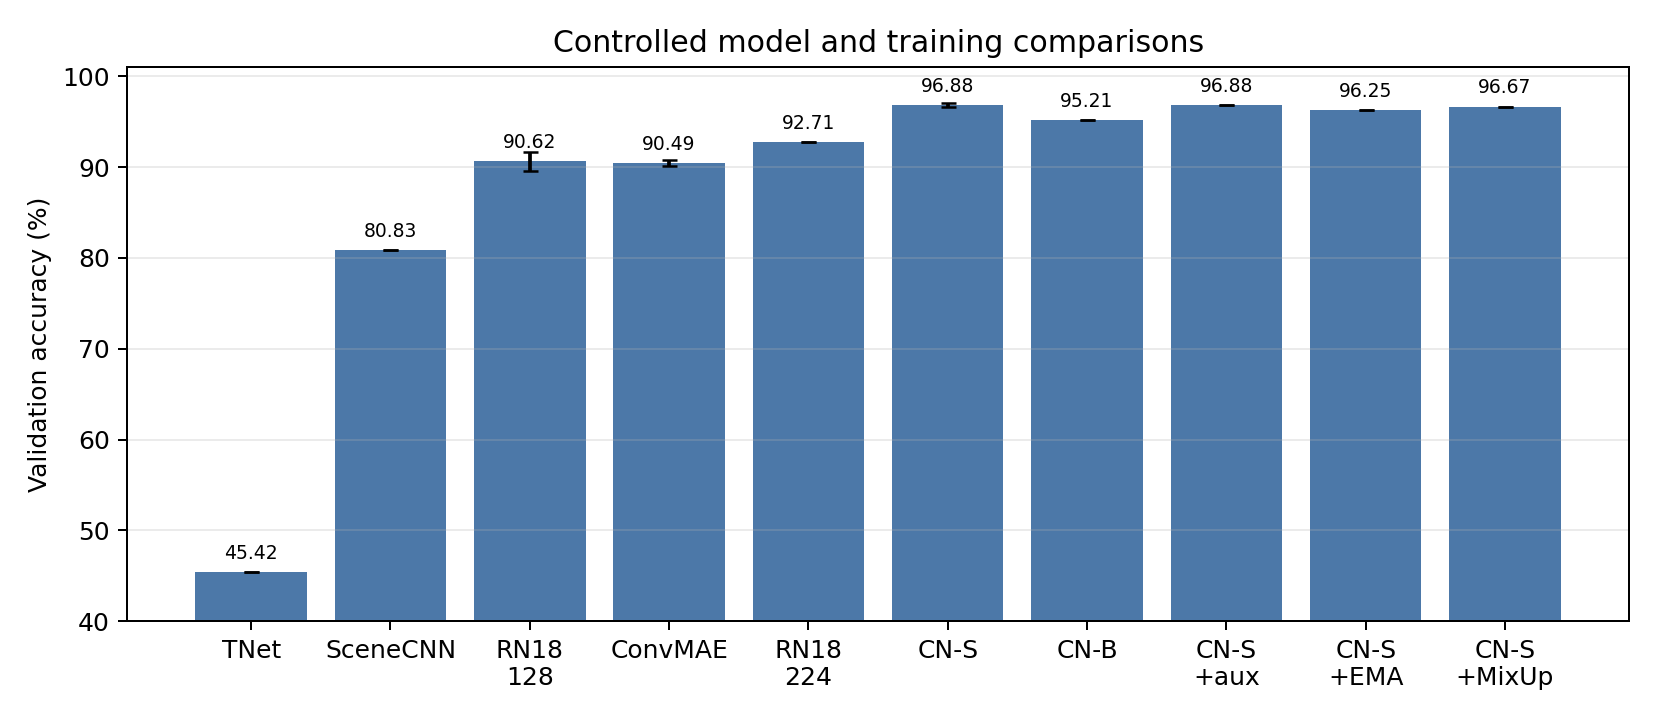

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "results/figures/validation_accuracy.png"), width=900))

## 3. Main findings

1. The starter TNet reached 45.42%; a residual SceneCNN plus augmentation reached 80.83%.
2. ImageNet-pretrained ResNet18 reached 90.62% ± 1.04% across three seeds—the largest clean improvement.
3. Increasing resolution to 224 and preserving more global scene layout raised ResNet18 to 92.71%.
4. ConvNeXt-Small reached 96.88% ± 0.21% across three seeds. ConvNeXt-Base fell to 95.21%, so more capacity was not beneficial.
5. The lightweight masked auxiliary model reached 96.88% validation and the best observed test result, 96.75%. Its 0.5-point test gain over the plain model is only two images and should not be over-interpreted.
6. EMA (96.25%) and MixUp (96.67%) did not improve validation performance.

## 4. Failure and error analysis

The separate convolutional MAE adaptation did not improve ResNet18: 90.49% ± 0.32% versus 90.62% ± 1.04% for direct ImageNet initialization. With only 1,920 unlabeled training images, blurry reconstruction supplied less useful information than large-scale supervised pretraining. This motivated a cheaper joint masked auxiliary head rather than longer standalone pretraining.

For the final model, `InsideCity` was the weakest test class (84%), followed by `Mountain` (92%). The errors concentrate in heterogeneous urban/outdoor categories whose boundaries depend on global context.

## 5. Reproduction

```bash
# Train the final recipe
conda run -n cv python train.py \
  --config configs/e9_convnext_small_masked_aux_224.json --device cuda

# Validate the compact exported checkpoint
conda run -n cv python evaluate.py \
  --checkpoint checkpoints/final_convnext_small_aux_fp16.pt \
  --split validation --device cuda

# Guarded final-test evaluation
conda run -n cv python evaluate.py \
  --checkpoint checkpoints/final_convnext_small_aux_fp16.pt \
  --split test --confirm-final-test --device cuda

# Regression tests
conda run -n cv python -m unittest discover -s tests -v
```

See `README.md`, `AI_USAGE.md`, `results/experiment_summary.json`, and the two-page PDF report for complete details.